In [4]:
import numpy as np
from utils.MyTools import MyTools
A = np.array([[3,0],[1,1]])
U,sigma,Vt = np.linalg.svd(A)
np.linalg.eig(A)
# torch.arange(0, 1024, dtype=torch.float).unsqueeze(1)
# torch.arange(0, d_model, 2).float(),torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model) ,-math.log(10000.0) / d_model
# torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))

EigResult(eigenvalues=array([1., 3.]), eigenvectors=array([[0.        , 0.89442719],
       [1.        , 0.4472136 ]]))

In [3]:
MyTools.myPlot

array([[3, 0],
       [1, 1]])

In [5]:
MyTools.myVectorArea(A)


np.float64(3.0000000000000004)

In [3]:
np.cross(A[:,0],A[:,1])
np


C:\Users\kim\AppData\Local\Temp\ipykernel_6476\410450663.py:1: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  np.cross(A[:,0],A[:,1])


array(3)

In [14]:
pe = torch.arange(20).reshape(4,5)
pe = pe.unsqueeze(0)

In [18]:
pe.transpose(0,1).shape




torch.Size([4, 1, 5])

In [29]:
p = PositionalEncoding(512)

In [34]:
p.ped.shape

torch.Size([5000, 256])

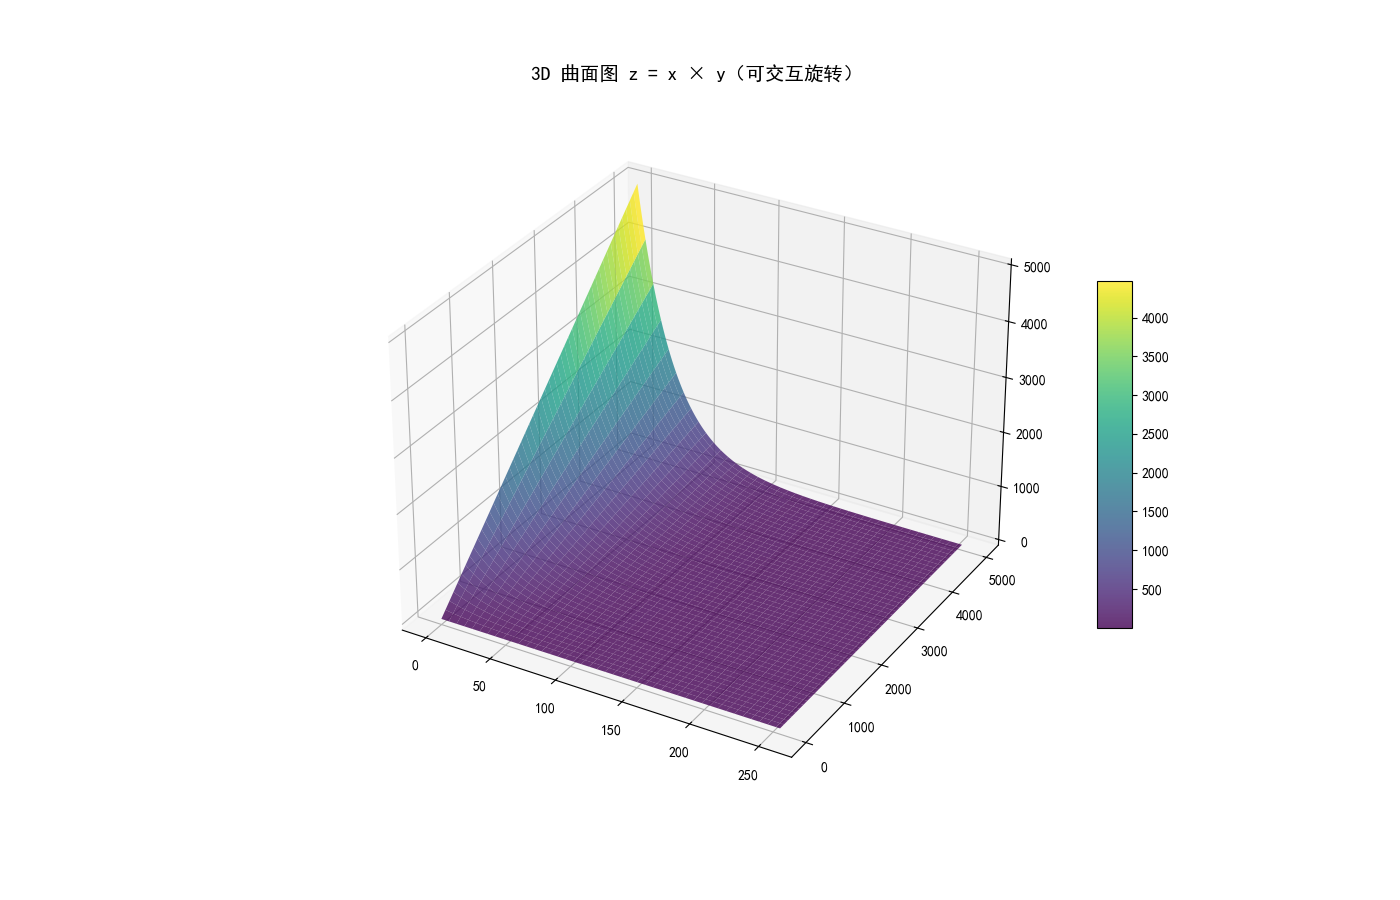

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [1.00000000e+00, 9.64661598e-01, 9.30572033e-01, ...,
        1.11397407e-04, 1.07460757e-04, 1.03663326e-04],
       [2.00000000e+00, 1.92932320e+00, 1.86114407e+00, ...,
        2.22794813e-04, 2.14921514e-04, 2.07326651e-04],
       ...,
       [4.99700000e+03, 4.82041406e+03, 4.65006836e+03, ...,
        5.56652844e-01, 5.36981404e-01, 5.18005610e-01],
       [4.99800000e+03, 4.82137891e+03, 4.65099902e+03, ...,
        5.56764245e-01, 5.37088871e-01, 5.18109322e-01],
       [4.99900000e+03, 4.82234326e+03, 4.65192969e+03, ...,
        5.56875646e-01, 5.37196338e-01, 5.18212974e-01]], dtype=float32)

In [33]:
%matplotlib widget
MyTools.myPlot3dDF(p.ped,p='N')

In [1]:
#修正后整体代码
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import numpy as np

# 设置随机种子保证可重复性
torch.manual_seed(42)

# 构建简化的词表
# src_vocab = {'<pad>': 0, '<sos>': 1, '<eos>': 2, 'I': 3, 'am': 4, 'a': 5, 'student': 6}
# tgt_vocab = {'<pad>': 0, '<sos>': 1, '<eos>': 2, '我': 3, '是': 4, '一个': 5, '学生': 6}
src_vocab = {'<pad>': 0, '<sos>': 1, 'I': 2, 'am': 3, 'a': 4, 'student': 5, '<eos>': 6}
tgt_vocab = {'<pad>': 0, '<sos>': 1, '我': 2, '是': 3, '一个': 4, '学生': 5, '<eos>': 6}
src_vocab_size = len(src_vocab)
tgt_vocab_size = len(tgt_vocab)

# 示例数据
src_sentence = ['I', 'am', 'a', 'student']
tgt_sentence = ['我', '是', '一个', '学生']

# 转换为索引
src_indices = [src_vocab[word] for word in src_sentence]
tgt_indices = [tgt_vocab[word] for word in tgt_sentence]

print("源句子索引:", src_indices)  # [3, 4, 5, 6]
print("目标句子索引:", tgt_indices)  # [3, 4, 5, 6]

# 修复后的多头注意力机制
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super(MultiHeadAttention, self).__init__()
        assert d_model % num_heads == 0
        
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads
        
        # 线性变换层
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        
    def scaled_dot_product_attention(self, Q, K, V, mask=None):
        # Q, K, V: [batch_size, num_heads, seq_len, d_k]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)
        
        attention_weights = F.softmax(scores, dim=-1)
        output = torch.matmul(attention_weights, V)
        
        return output, attention_weights
    
    def forward(self, Q, K, V, mask=None):
        batch_size = Q.size(0)
        
        # 线性变换并分头 - 修复：分别处理Q、K、V的序列长度
        Q = self.W_q(Q).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(K).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(V).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        
        # 计算注意力
        attn_output, attn_weights = self.scaled_dot_product_attention(Q, K, V, mask)
        
        
        # 合并多头
        attn_output = attn_output.transpose(1, 2).contiguous().view(
            batch_size, -1, self.d_model)

 
        # 输出线性变换
        output = self.W_o(attn_output)
        
        return output, attn_weights

# 位置编码（保持不变）
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * 
                           (-math.log(10000.0) / d_model))
        
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        
        pe = pe.unsqueeze(0).transpose(0, 1)
        self.register_buffer('ped',position * div_term)
        self.register_buffer('pe', pe)
    
    def forward(self, x):
        return x + self.pe[:x.size(0), :]

# 前馈网络（保持不变）
class PositionWiseFFN(nn.Module):
    def __init__(self, d_model, d_ff):
        super(PositionWiseFFN, self).__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(0.1)
        
    def forward(self, x):
        return self.linear2(self.dropout(F.relu(self.linear1(x))))

# 编码器层（保持不变）
class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super(EncoderLayer, self).__init__()
        self.self_attention = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = PositionWiseFFN(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x, mask=None):
        # 自注意力子层
        attn_output, _ = self.self_attention(x, x, x, mask)
        x = self.norm1(x + self.dropout(attn_output))
        
        # 前馈网络子层
        ffn_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ffn_output))
        
        return x

# 解码器层（保持不变）
class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super(DecoderLayer, self).__init__()
        self.self_attention = MultiHeadAttention(d_model, num_heads)
        self.cross_attention = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = PositionWiseFFN(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x, enc_output, src_mask=None, tgt_mask=None):
        # 掩码自注意力子层
        self_attn_output, _ = self.self_attention(x, x, x, tgt_mask)
        x = self.norm1(x + self.dropout(self_attn_output))
        
        # 编码器-解码器注意力子层
        cross_attn_output, _ = self.cross_attention(x, enc_output, enc_output, src_mask)
        x = self.norm2(x + self.dropout(cross_attn_output))
        
        # 前馈网络子层
        ffn_output = self.feed_forward(x)
        x = self.norm3(x + self.dropout(ffn_output))
        
        return x

# 修复后的Transformer模型
class Transformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model, num_heads, num_layers, d_ff, max_seq_length, dropout=0.1):
        super(Transformer, self).__init__()
        self.d_model = d_model
        self.encoder_embedding = nn.Embedding(src_vocab_size, d_model)
        self.decoder_embedding = nn.Embedding(tgt_vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_seq_length)
        
        self.encoder_layers = nn.ModuleList([
            EncoderLayer(d_model, num_heads, d_ff, dropout) 
            for _ in range(num_layers)
        ])
        
        self.decoder_layers = nn.ModuleList([
            DecoderLayer(d_model, num_heads, d_ff, dropout) 
            for _ in range(num_layers)
        ])
        
        self.fc_out = nn.Linear(d_model, tgt_vocab_size)
        self.dropout = nn.Dropout(dropout)
        
    def generate_mask(self, src, tgt):
        # 源序列掩码 (处理padding)
        src_mask = (src != 0).unsqueeze(1).unsqueeze(2)
        
        # 目标序列掩码 (防止看到未来信息)
        tgt_len = tgt.shape[1]
        tgt_mask = torch.tril(torch.ones(tgt_len, tgt_len)).bool()
        tgt_mask = tgt_mask.unsqueeze(0).unsqueeze(1)
        
        return src_mask, tgt_mask
    
    def forward(self, src, tgt):
        # 生成掩码
        src_mask, tgt_mask = self.generate_mask(src, tgt)
        
        # 编码器
        src_embedded = self.dropout(self.positional_encoding(self.encoder_embedding(src) * math.sqrt(self.d_model)))
        enc_output = src_embedded
        for enc_layer in self.encoder_layers:
            enc_output = enc_layer(enc_output, src_mask)
        
        # 解码器
        tgt_embedded = self.dropout(self.positional_encoding(self.decoder_embedding(tgt) * math.sqrt(self.d_model)))
        dec_output = tgt_embedded
        for dec_layer in self.decoder_layers:
            dec_output = dec_layer(dec_output, enc_output, src_mask, tgt_mask)
        
        # 输出层
        output = self.fc_out(dec_output)
        return output

# 参数设置
d_model = 512
num_heads = 8
d_ff = 2048
num_layers = 2
max_seq_length = 1000

# 创建模型
model = Transformer(
    src_vocab_size=src_vocab_size,
    tgt_vocab_size=tgt_vocab_size,
    d_model=d_model,
    num_heads=num_heads,
    num_layers=num_layers,
    d_ff=d_ff,
    max_seq_length=max_seq_length
)

print("模型参数量:", sum(p.numel() for p in model.parameters()))

# 准备数据
src_tensor = torch.tensor([src_indices])  # 添加batch维度
tgt_tensor = torch.tensor([tgt_indices])

print("源序列形状:", src_tensor.shape)
print("目标序列形状:", tgt_tensor.shape)

# 训练配置
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, betas=(0.9, 0.98), eps=1e-9)
criterion = nn.CrossEntropyLoss(ignore_index=0)  # 忽略padding

# 修复后的训练步骤
def train_step(model, src, tgt, optimizer, criterion):
    model.train()
    optimizer.zero_grad()
    
    # 前向传播 - 注意：解码器输入是目标序列的前n-1个词
    output = model(src, tgt[:, :-1])
    
    # 计算损失 - 目标是目标序列的后n-1个词
    output = output.reshape(-1, output.shape[-1])
    tgt_output = tgt[:, 1:].reshape(-1)
    
    loss = criterion(output, tgt_output)
    
    # 反向传播
    loss.backward()
    optimizer.step()
    
    return loss.item()

# 训练过程
print("\n=== 训练过程 ===")
for epoch in range(10):  # 增加训练轮数
    loss = train_step(model, src_tensor, tgt_tensor, optimizer, criterion)
    if (epoch + 1) % 2 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss:.4f}")

# 修复后的推理函数
def translate(model, src_sentence, src_vocab, tgt_vocab, max_length=10):
    model.eval()
    
    # 反转词表，用于索引到词的转换
    idx_to_word = {idx: word for word, idx in tgt_vocab.items()}
    # print(idx_to_word)
    
    # 将源句子转换为索引
    src_indices = [src_vocab[word] for word in src_sentence]
    # print(src_indices)
    src_tensor = torch.tensor([src_indices])
    # print(src_tensor)
    
    # 开始解码
    tgt_indices = [tgt_vocab['<sos>']]  # 起始符
    
    for i in range(max_length):
        tgt_tensor = torch.tensor([tgt_indices])
        # print(tgt_tensor)
        with torch.no_grad():
            output = model(src_tensor, tgt_tensor)
        # print(src_tensor, tgt_tensor )
        # print(output)
        # 获取下一个词的预测
        next_word_logits = output[0, -1, :]
        next_word_index = torch.argmax(next_word_logits).item()
        
        tgt_indices.append(next_word_index)
        print(tgt_indices)
        # 如果遇到结束符则停止
        if next_word_index == tgt_vocab['<eos>']:
            print('break')
            break
    
    # 将索引转换回单词（跳过起始符）
    tgt_words = [idx_to_word[idx] for idx in tgt_indices[1:] if idx != tgt_vocab['<eos>']]
    
    return ''.join(tgt_words)

# 测试翻译
print("\n=== 翻译测试 ===")
translation = translate(model, src_sentence, src_vocab, tgt_vocab)
print(f"源句子: {' '.join(src_sentence)}")
print(f"目标句子: {' '.join(tgt_sentence)}")
print(f"模型翻译: {translation}")

# 测试模型前向传播
print("\n=== 模型前向传播测试 ===")
with torch.no_grad():
    test_output = model(src_tensor, tgt_tensor[:, :-1])
    print(f"模型输出形状: {test_output.shape}")  # 应该是 [1, 3, tgt_vocab_size]
    print(f"词汇表大小: {tgt_vocab_size}")


源句子索引: [2, 3, 4, 5]
目标句子索引: [2, 3, 4, 5]
模型参数量: 14723591
源序列形状: torch.Size([1, 4])
目标序列形状: torch.Size([1, 4])

=== 训练过程 ===
Epoch 2, Loss: 0.8848
Epoch 4, Loss: 0.1782
Epoch 6, Loss: 0.0449
Epoch 8, Loss: 0.0143
Epoch 10, Loss: 0.0073

=== 翻译测试 ===
[1, 5]
[1, 5, 5]
[1, 5, 5, 5]
[1, 5, 5, 5, 5]
[1, 5, 5, 5, 5, 5]
[1, 5, 5, 5, 5, 5, 5]
[1, 5, 5, 5, 5, 5, 5, 5]
[1, 5, 5, 5, 5, 5, 5, 5, 5]
[1, 5, 5, 5, 5, 5, 5, 5, 5, 5]
[1, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5]
源句子: I am a student
目标句子: 我 是 一个 学生
模型翻译: 学生学生学生学生学生学生学生学生学生学生

=== 模型前向传播测试 ===
模型输出形状: torch.Size([1, 3, 7])
词汇表大小: 7


tensor([[2, 3, 4, 5]])

In [5]:

W_q = nn.Linear(d_model, d_model)
W_k = nn.Linear(d_model, d_model)
W_v = nn.Linear(d_model, d_model)
W_o = nn.Linear(d_model, d_model)

torch.Size([1, 8, 4, 4])

In [17]:
batch_size

1

In [24]:
#学习多头注意力

num_heads = 8
d_k = d_model//num_heads
attention = MultiHeadAttention(d_model, num_heads) #生成随机的 W_q,W_k,W_v,W_o

# 模拟输入 (batch_size=1, seq_len=4, d_model=512)
x = torch.randn(1, 4, d_model)
batch_size = x.shape[0]
output, weights = attention(x, x, x) # Q,K,V,mask。相当于计算自注意力。
l1 = attention.W_q(x).view(batch_size, -1, num_heads, d_k).transpose(1, 2)
l2 = attention.W_k(x).view(batch_size, -1, num_heads, d_k).transpose(1, 2)
l3 = attention.W_v(x).view(batch_size, -1, num_heads, d_k).transpose(1, 2)
o,w = scaled_dot_product_attention(l1,l2,l3)
attn_output = o.transpose(1, 2).contiguous().view(1, -1, 512)
output2 = attention.W_o(attn_output)

print("自注意力输出形状:", output.shape)
print("注意力权重形状:", weights.shape)



自注意力输出形状: torch.Size([1, 4, 512])
注意力权重形状: torch.Size([1, 8, 4, 4])


In [30]:
x.shape

torch.Size([1, 4, 512])

原始 Q/K/V shape: torch.Size([1, 10, 128])
分头后 Q shape: torch.Size([1, 4, 10, 32])
单头注意力分数shape:  torch.Size([1, 4, 10, 10])
单头注意力权重shape:  torch.Size([1, 4, 10, 10])


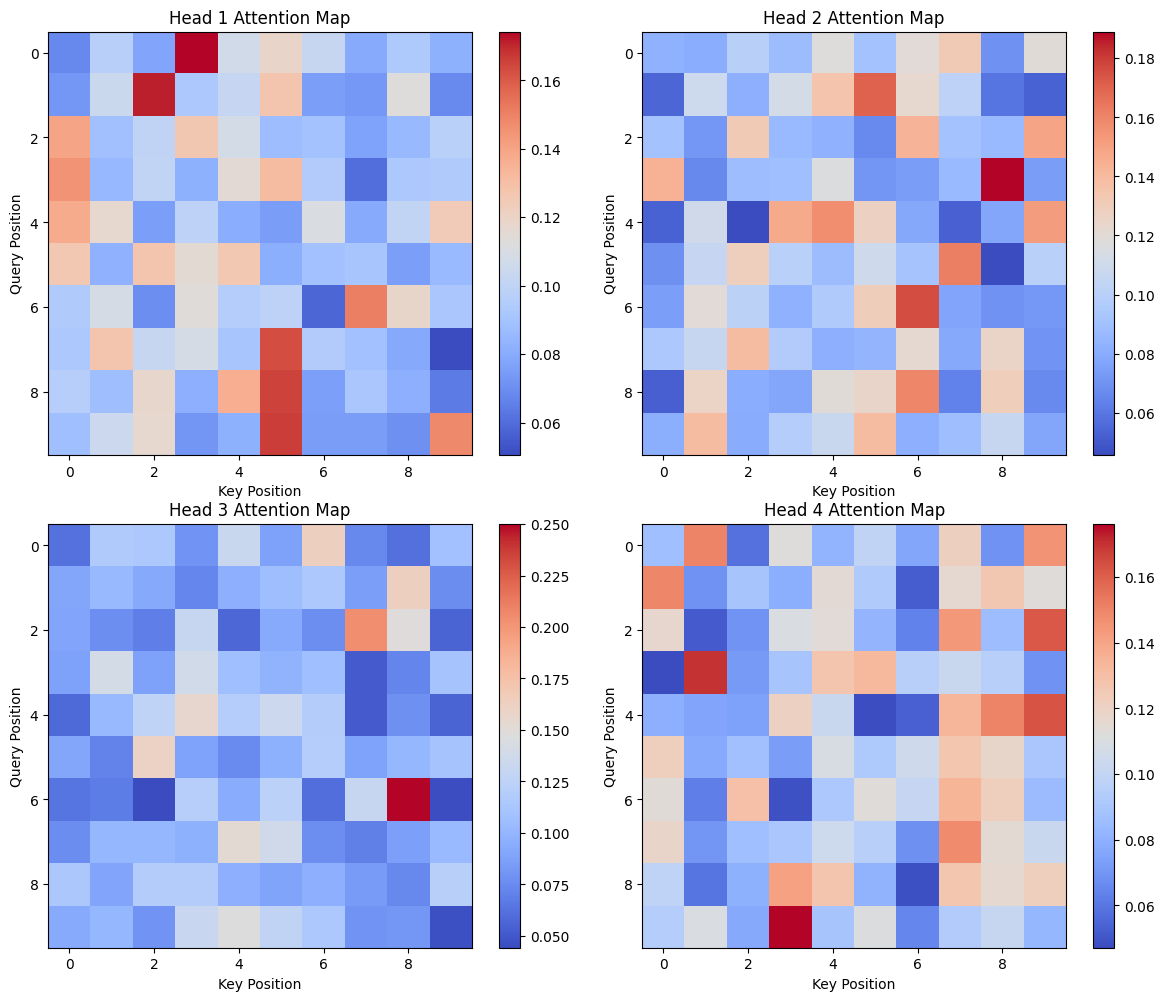

In [7]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ===================== 超参 =====================
batch_size = 1
seq_len    = 10    # 序列长度
d_model    = 128   # 总维度
num_heads  = 4     # 多头数
d_k        = d_model // num_heads  # 单头维度

# ===================== 1. 构造输入 =====================
x = torch.randn(batch_size, seq_len, d_model)   # [B, L, D]

# ===================== 2. 手动 Q/K/V 投影 =====================
w_q = nn.Linear(d_model, d_model)
w_k = nn.Linear(d_model, d_model)
w_v = nn.Linear(d_model, d_model)
w_o = nn.Linear(d_model, d_model)

Q = w_q(x)
K = w_k(x)
V = w_v(x)

print("原始 Q/K/V shape:", Q.shape)

# ===================== 3. 分头 [B, head, L, dk] =====================
def split_head(tensor, heads):
    B, L, D = tensor.shape
    return tensor.reshape(B, L, heads, d_k).transpose(1, 2)

Q = split_head(Q, num_heads)   # [B, H, L, dk]
K = split_head(K, num_heads)
V = split_head(V, num_heads)

print("分头后 Q shape:", Q.shape)

# ===================== 4. 计算注意力 =====================
# 1. 注意力分数 Q @ K^T
attn_score = torch.matmul(Q, K.transpose(-2, -1)) / torch.sqrt(torch.tensor(d_k, dtype=torch.float32))
# 2. softmax 得到注意力权重
attn_weight = torch.softmax(attn_score, dim=-1)   # [B, H, L, L]
# 3. 加权 V
out = torch.matmul(attn_weight, V)

print("单头注意力分数shape: ", attn_score.shape)
print("单头注意力权重shape: ", attn_weight.shape)

# ===================== 5. 逐个 head 绘制热力图 =====================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for h in range(num_heads):
    # 取出当前头的注意力矩阵 [seq_len, seq_len]
    head_attn = attn_weight[0, h].detach().cpu().numpy()
    ax = axes[h]
    im = ax.imshow(head_attn, cmap="coolwarm")
    ax.set_title(f"Head {h+1} Attention Map")
    ax.set_xlabel("Key Position")
    ax.set_ylabel("Query Position")
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()


In [ ]:
#学习位置编码




In [ ]:
#deepseek给的示例
#环境设置
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import numpy as np

# 设置随机种子保证可重复性
torch.manual_seed(42)

In [1]:
#1. 数据准备和词表构建
# 构建简化的词表
src_vocab = {'<pad>': 0, '<sos>': 1, '<eos>': 2, 'I': 3, 'am': 4, 'a': 5, 'student': 6}
tgt_vocab = {'<pad>': 0, '<sos>': 1, '<eos>': 2, '我': 3, '是': 4, '一个': 5, '学生': 6}
src_vocab_size = len(src_vocab)
tgt_vocab_size = len(tgt_vocab)

# 示例数据
src_sentence = ['I', 'am', 'a', 'student']
tgt_sentence = ['我', '是', '一个', '学生']

# 转换为索引
src_indices = [src_vocab[word] for word in src_sentence]
tgt_indices = [tgt_vocab[word] for word in tgt_sentence]

print("源句子索引:", src_indices)  # [3, 4, 5, 6]
print("目标句子索引:", tgt_indices)  # [3, 4, 5, 6]

源句子索引: [3, 4, 5, 6]
目标句子索引: [3, 4, 5, 6]


In [3]:
#2. 位置编码
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        
        # 创建位置编码矩阵
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * 
                           (-math.log(10000.0) / d_model))
        
        # 正弦波用于偶数位置
        pe[:, 0::2] = torch.sin(position * div_term)
        # 余弦波用于奇数位置  
        pe[:, 1::2] = torch.cos(position * div_term)
        
        pe = pe.unsqueeze(0).transpose(0, 1)
        self.register_buffer('pe', pe)
    
    def forward(self, x):
        # x: [seq_len, batch_size, d_model]
        return x + self.pe[:x.size(0), :]

# 测试位置编码
d_model = 512
pos_encoder = PositionalEncoding(d_model)
print("位置编码形状示例:", pos_encoder.pe.shape)

位置编码形状示例: torch.Size([5000, 1, 512])


In [2]:
#3. 自注意力机制
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super(MultiHeadAttention, self).__init__()
        assert d_model % num_heads == 0
        
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads
        
        # 线性变换层
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        
    def scaled_dot_product_attention(self, Q, K, V, mask=None):
        # Q, K, V: [batch_size, num_heads, seq_len, d_k]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)
        
        attention_weights = F.softmax(scores, dim=-1)
        output = torch.matmul(attention_weights, V)
        
        return output, attention_weights
    
    def forward(self, Q, K, V, mask=None):
        batch_size, seq_len = Q.size(0), Q.size(1)
        
        # 线性变换并分头
        Q = self.W_q(Q).view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(K).view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(V).view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        
        # 计算注意力
        attn_output, attn_weights = self.scaled_dot_product_attention(Q, K, V, mask)
        
        # 合并多头
        attn_output = attn_output.transpose(1, 2).contiguous().view(
            batch_size, seq_len, self.d_model)
        
        # 输出线性变换
        output = self.W_o(attn_output)
        
        return output, attn_weights

# 测试自注意力
num_heads = 8
attention = MultiHeadAttention(d_model, num_heads)

# 模拟输入 (batch_size=1, seq_len=4, d_model=512)
x = torch.randn(1, 4, d_model)
output, weights = attention(x, x, x)
print("自注意力输出形状:", output.shape)
print("注意力权重形状:", weights.shape)

自注意力输出形状: torch.Size([1, 4, 512])
注意力权重形状: torch.Size([1, 8, 4, 4])


In [5]:
#4. 前馈网络
class PositionWiseFFN(nn.Module):
    def __init__(self, d_model, d_ff):
        super(PositionWiseFFN, self).__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(0.1)
        
    def forward(self, x):
        return self.linear2(self.dropout(F.relu(self.linear1(x))))

# 测试前馈网络
d_ff = 2048
ffn = PositionWiseFFN(d_model, d_ff)
ffn_output = ffn(output)
print("前馈网络输出形状:", ffn_output.shape)

前馈网络输出形状: torch.Size([1, 4, 512])


In [6]:
#5. 编码器层
class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super(EncoderLayer, self).__init__()
        self.self_attention = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = PositionWiseFFN(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x, mask=None):
        # 自注意力子层
        attn_output, _ = self.self_attention(x, x, x, mask)
        x = self.norm1(x + self.dropout(attn_output))
        
        # 前馈网络子层
        ffn_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ffn_output))
        
        return x

# 测试编码器层
encoder_layer = EncoderLayer(d_model, num_heads, d_ff)
encoder_output = encoder_layer(x)
print("编码器层输出形状:", encoder_output.shape)

编码器层输出形状: torch.Size([1, 4, 512])


In [7]:
#6. 解码器层
class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super(DecoderLayer, self).__init__()
        self.self_attention = MultiHeadAttention(d_model, num_heads)
        self.cross_attention = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = PositionWiseFFN(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x, enc_output, src_mask=None, tgt_mask=None):
        # 掩码自注意力子层
        self_attn_output, _ = self.self_attention(x, x, x, tgt_mask)
        x = self.norm1(x + self.dropout(self_attn_output))
        
        # 编码器-解码器注意力子层
        cross_attn_output, _ = self.cross_attention(x, enc_output, enc_output, src_mask)
        x = self.norm2(x + self.dropout(cross_attn_output))
        
        # 前馈网络子层
        ffn_output = self.feed_forward(x)
        x = self.norm3(x + self.dropout(ffn_output))
        
        return x

# 测试解码器层
decoder_layer = DecoderLayer(d_model, num_heads, d_ff)
decoder_output = decoder_layer(x, encoder_output)
print("解码器层输出形状:", decoder_output.shape)

解码器层输出形状: torch.Size([1, 4, 512])


In [8]:
#7. 完整的 Transformer 模型
class Transformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model, num_heads, num_layers, d_ff, max_seq_length, dropout=0.1):
        super(Transformer, self).__init__()
        self.encoder_embedding = nn.Embedding(src_vocab_size, d_model)
        self.decoder_embedding = nn.Embedding(tgt_vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_seq_length)
        
        self.encoder_layers = nn.ModuleList([
            EncoderLayer(d_model, num_heads, d_ff, dropout) 
            for _ in range(num_layers)
        ])
        
        self.decoder_layers = nn.ModuleList([
            DecoderLayer(d_model, num_heads, d_ff, dropout) 
            for _ in range(num_layers)
        ])
        
        self.fc_out = nn.Linear(d_model, tgt_vocab_size)
        self.dropout = nn.Dropout(dropout)
        
    def generate_mask(self, src, tgt):
        # 源序列掩码 (处理padding)
        src_mask = (src != 0).unsqueeze(1).unsqueeze(2)
        
        # 目标序列掩码 (防止看到未来信息)
        tgt_len = tgt.shape[1]
        tgt_mask = torch.tril(torch.ones(tgt_len, tgt_len)).bool()
        tgt_mask = tgt_mask.unsqueeze(0).unsqueeze(1)
        
        return src_mask, tgt_mask
    
    def forward(self, src, tgt):
        # 生成掩码
        src_mask, tgt_mask = self.generate_mask(src, tgt)
        
        # 编码器
        src_embedded = self.dropout(self.positional_encoding(self.encoder_embedding(src)))
        enc_output = src_embedded
        for enc_layer in self.encoder_layers:
            enc_output = enc_layer(enc_output, src_mask)
        
        # 解码器
        tgt_embedded = self.dropout(self.positional_encoding(self.decoder_embedding(tgt)))
        dec_output = tgt_embedded
        for dec_layer in self.decoder_layers:
            dec_output = dec_layer(dec_output, enc_output, src_mask, tgt_mask)
        
        # 输出层
        output = self.fc_out(dec_output)
        return output

# 创建完整的Transformer模型
num_layers = 2  # 简化，原论文是6层
max_seq_length = 10

model = Transformer(
    src_vocab_size=src_vocab_size,
    tgt_vocab_size=tgt_vocab_size,
    d_model=d_model,
    num_heads=num_heads,
    num_layers=num_layers,
    d_ff=d_ff,
    max_seq_length=max_seq_length
)

print("模型参数量:", sum(p.numel() for p in model.parameters()))

模型参数量: 14723591


In [ ]:
#8. 训练过程示例，这部分有错误。
def train_step(model, src, tgt, optimizer, criterion):
    model.train()
    optimizer.zero_grad()
    
    # 前向传播
    output = model(src, tgt[:, :-1])  # 输入到解码器的是目标序列的前n-1个词
    
    # 计算损失
    output = output.reshape(-1, output.shape[-1])
    tgt = tgt[:, 1:].reshape(-1)  # 目标是目标序列的后n-1个词
    
    loss = criterion(output, tgt)
    
    # 反向传播
    loss.backward()
    optimizer.step()
    
    return loss.item()

# 准备数据
src_tensor = torch.tensor([src_indices])  # 添加batch维度
tgt_tensor = torch.tensor([tgt_indices])

print("源序列:", src_tensor.shape)
print("目标序列:", tgt_tensor.shape)

# 训练配置
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
criterion = nn.CrossEntropyLoss(ignore_index=0)  # 忽略padding

# 模拟训练步骤
print("\n=== 训练过程示例 ===")
for epoch in range(3):  # 简化训练轮数
    loss = train_step(model, src_tensor, tgt_tensor, optimizer, criterion)
    print(f"Epoch {epoch+1}, Loss: {loss:.4f}")

# 推理示例
def translate(model, src_sentence, src_vocab, tgt_vocab):
    model.eval()
    
    # 将源句子转换为索引
    src_indices = [src_vocab[word] for word in src_sentence]
    src_tensor = torch.tensor([src_indices])
    
    # 开始解码
    tgt_indices = [tgt_vocab['<sos>']]  # 起始符
    
    for i in range(max_seq_length):
        tgt_tensor = torch.tensor([tgt_indices])
        
        with torch.no_grad():
            output = model(src_tensor, tgt_tensor)
            
        # 获取下一个词的预测
        next_word_logits = output[0, -1, :]
        next_word_index = torch.argmax(next_word_logits).item()
        
        tgt_indices.append(next_word_index)
        
        # 如果遇到结束符则停止
        if next_word_index == tgt_vocab['<eos>']:
            break
    
    # 将索引转换回单词
    tgt_words = []
    for idx in tgt_indices[1:]:  # 跳过起始符
        if idx == tgt_vocab['<eos>']:
            break
        for word, word_idx in tgt_vocab.items():
            if word_idx == idx:
                tgt_words.append(word)
                break
    
    return ' '.join(tgt_words)

# 测试翻译
translation = translate(model, src_sentence, src_vocab, tgt_vocab)
print(f"\n翻译结果: '{' '.join(src_sentence)}' -> '{translation}'")

源句子索引: [3, 4, 5, 6]
目标句子索引: [3, 4, 5, 6]
模型参数量: 14723591
源序列形状: torch.Size([1, 4])
目标序列形状: torch.Size([1, 4])

=== 训练过程 ===
Epoch 2, Loss: 0.7786
Epoch 4, Loss: 0.1446
Epoch 6, Loss: 0.0423
Epoch 8, Loss: 0.0116
Epoch 10, Loss: 0.0060

=== 翻译测试 ===
源句子: I am a student
目标句子: 我 是 一个 学生
模型翻译: 学生是一个学生学生学生学生学生学生学生

=== 模型前向传播测试 ===
模型输出形状: torch.Size([1, 3, 7])
词汇表大小: 7
